# Fitting decay data

In [1]:
import ROOT
import numpy as np
from array import array
import matplotlib.pyplot as plt
from uncertainties import ufloat
from dataclasses import dataclass
from uncertainties import unumpy as unp

thalf_137Ba_nudat = 2.5518*60  # seconds
thalf_234Pa_nudat = 1.159*60   # seconds

# Some useful settings for ROOT
# We want the statistics box to be displayed and the fit information to appear in the box
ROOT.gROOT.SetStyle("Plain")
ROOT.gStyle.SetOptStat()
ROOT.gStyle.SetOptFit(11111111)

@dataclass
class Data:
    x_val:      np.ndarray
    y_val:      np.ndarray
    y_errs:     np.ndarray
    y_val_log:  np.ndarray
    y_errs_log: np.ndarray

## Experiment 1: Geiger Counter

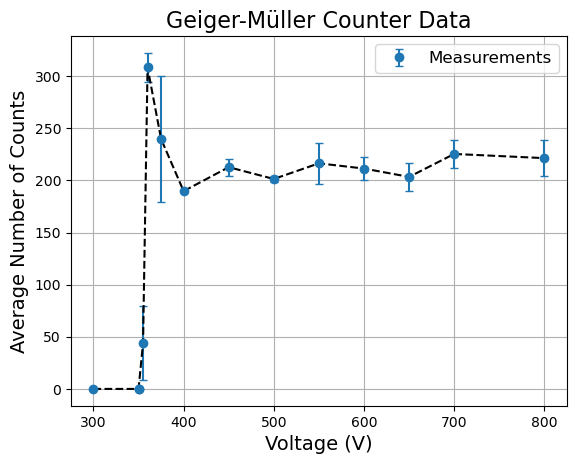

In [2]:
V = [300, 350, 400, 450, 500, 550, 600, 650, 700, 800, 375, 360, 350, 355]
counts = np.array([
    [  0,   0,   0],
    [  0,   0,   0],
    [191, 190, 188],
    [205, 224, 209],
    [199, 206, 199],
    [196, 243, 210],
    [200, 226, 208],
    [188, 202, 220],
    [244, 211, 221],
    [197, 238, 229],
    [248, 162, 309],
    [315, 289, 321],
    [  0,   0,   0],
    [ 94,  17,  21]
])

counts = unp.uarray(np.mean(counts, axis=1), np.std(counts, axis=1))
idx    = np.argsort(V)
V      = np.array(V)[idx]
counts = counts[idx]

plt.errorbar(V, unp.nominal_values(counts), yerr=unp.std_devs(counts), fmt='o', label='Measurements', capsize=3)
plt.plot(V, unp.nominal_values(counts), linestyle='--', color='black')
plt.xlabel('Voltage (V)', fontsize=14)
plt.ylabel('Average Number of Counts', fontsize=14)
plt.grid()
plt.title('Geiger-Müller Counter Data', fontsize=16)

plt.legend(fontsize=12)
plt.savefig('GM.pdf')
plt.show()

## Experiment 2: $^{137}_{56}\text{Ba}^m$ Half-life

In [3]:
B_raw = 37 
B = ufloat(B_raw, np.sqrt(B_raw)) / 10  # Background count rate in counts/sec
print(f'Background count rate B = {B:.2f} [counts/10 sec]')

counts_raw = np.array([159, 104, 89, 79, 72, 67, 51, 51, 38, 37, 33, 38, 23, 22, 22, 12, 10,  
                        20,  15,  8,  9,  8,  7, 10, 11,  4,  7,  4,  7,  6,  3,  7,  5,  1])

counts = unp.uarray(counts_raw, np.sqrt(counts_raw)) - B  # Subtract background count rate
valid_indices = unp.nominal_values(counts) > 0  # Only keep positive values for logarithm
counts = counts[valid_indices]  # Filter counts to only include valid indices

x_val     = np.arange(0, 990+30, 30, dtype=np.float64)
x_val     = x_val[valid_indices]
y_val     = unp.nominal_values(counts)
y_errs    = unp.std_devs(counts)  # Assuming Poisson statistics for the counts
y_log     = np.log(y_val)
y_logerrs = np.sqrt(y_val) / y_val  


Ba_137_data = Data(x_val      = x_val, 
                   y_val      = y_val, 
                   y_errs     = y_errs, 
                   y_val_log  = y_log, 
                   y_errs_log = y_logerrs)

Background count rate B = 3.70+/-0.61 [counts/10 sec]


In [4]:

canvas1 = ROOT.TCanvas("canvas1","Raw data",800,600);

graph1 = ROOT.TGraphErrors(len(Ba_137_data.x_val),Ba_137_data.x_val,Ba_137_data.y_val,ROOT.nullptr,Ba_137_data.y_errs)
graph1.Draw("APE")

graph1.SetTitle("^{137}_{56}Ba^{m} Exponential decay curve;time (sec);counts/sec");
graph1.SetMarkerStyle(20);
graph1.SetLineColor(ROOT.kBlack);

# define the fit function
fexp = ROOT.TF1("fexp","expo(0)",20.0,300.0);
fexp.SetLineColor(ROOT.kRed);
fexp.SetLineStyle(1);
fexp.SetParNames("log(A_0)","Decay constant");

# Fit it to the graph and draw it
gf = graph1.Fit("fexp","S");
fexp.Draw("Same");

# Display the plot 
canvas1.Draw()
canvas1.SaveAs("Ba137_decay_fit.pdf")


# Calculate the half-life from the fitted decay constant (lambda or 1/lifetime)
thalf  = -np.log(2)/gf.Value(1)
dthalf =  np.log(2)*gf.Error(1)/gf.Value(1)**2

print('Half-life =',"{:.1f}".format(thalf),'+-',"{:.1f}".format(dthalf),'s')
print('Half-life =',"{:.4f}".format(thalf/60),'+-',"{:.4f}".format(dthalf/60),'min')
print(f'Half-life from nudat: {thalf_137Ba_nudat/60:.4f} min')
print(f'Difference: {abs(thalf - thalf_137Ba_nudat)/60:.4f} min')
print(f'Percentage difference: {abs(thalf - thalf_137Ba_nudat)/thalf_137Ba_nudat*100:.2f}%')

Half-life = 133.6 +- 6.1 s
Half-life = 2.2273 +- 0.1019 min
Half-life from nudat: 2.5518 min
Difference: 0.3245 min
Percentage difference: 12.72%
****************************************
Minimizer is Minuit2 / Migrad
Chi2                      =      24.6282
NDf                       =           30
Edm                       =  4.12571e-07
NCalls                    =           48
log(A_0)                  =      4.86209   +/-   0.0502132   
Decay constant            =  -0.00518685   +/-   0.00023719  


Info in <TCanvas::Print>: pdf file Ba137_decay_fit.pdf has been created


In [5]:
canvas2 = ROOT.TCanvas("canvas2","Linearized",800,600);

graph2 = ROOT.TGraphErrors(len(Ba_137_data.x_val),Ba_137_data.x_val,Ba_137_data.y_val_log,ROOT.nullptr,Ba_137_data.y_errs_log)
graph2.Draw("APE")

graph2.SetTitle("^{137}_{56}Ba^{m} Exponential decay curve;time (sec);log(counts/sec)");
graph2.SetMarkerStyle(20);
graph2.SetLineColor(ROOT.kBlack);

# define the linear fit function
flin = ROOT.TF1("flin","pol1",20,300);
flin.SetLineColor(ROOT.kBlue);
flin.SetLineStyle(1);
flin.SetParNames("Intercept","Slope");

# Fit it to the graph and draw it
gf = graph2.Fit("flin","S");
flin.Draw("Same");

# Display the plot
canvas2.Draw()
canvas2.SaveAs("Ba137_decay_fit_log.pdf")

# Calculate the half-life from the fitted decay constant (lambda or 1/lifetime)
thalf = -np.log(2)/gf.Value(1)
dthalf = np.log(2)*gf.Error(1)/gf.Value(1)**2

print('Half-life =',"{:.1f}".format(thalf),'+-',"{:.1f}".format(dthalf),'s')
print('Half-life =',"{:.4f}".format(thalf/60),'+-',"{:.4f}".format(dthalf/60),'min')
print(f'Half-life from nudat: {thalf_137Ba_nudat/60:.4f} min')
print(f'Difference: {abs(thalf - thalf_137Ba_nudat)/60:.4f} min')
print(f'Percentage difference: {abs(thalf - thalf_137Ba_nudat)/thalf_137Ba_nudat*100:.2f}%')

Half-life = 145.3 +- 5.4 s
Half-life = 2.4220 +- 0.0904 min
Half-life from nudat: 2.5518 min
Difference: 0.1298 min
Percentage difference: 5.08%
****************************************
Minimizer is Linear / Migrad
Chi2                      =      35.2827
NDf                       =           30
Intercept                 =      4.83859   +/-   0.0458381   
Slope                     =   -0.0047697   +/-   0.000178099 


Info in <TCanvas::Print>: pdf file Ba137_decay_fit_log.pdf has been created


## Experiment 3: $^{234}_{91}\text{Pa}^m$ Half-life

In [6]:
B1, B2, B3 = 30, 22, 27
B_raw = unp.uarray([B1, B2, B3], [np.sqrt(B1), np.sqrt(B2), np.sqrt(B3)]) / 6
B = sum(B_raw) / len(B_raw)
print(f'Average background count rate: {B:.2f} [counts/60 sec]')
counts_raw = np.array([75, 42, 43, 49, 41, 20, 16, 21, 15, 13, 12, 11, 13,
                       13, 5, 8, 11, 7, 7, 5, 7, 5, 4, 6, 4, 8])

counts = unp.uarray(counts_raw, np.sqrt(counts_raw)) - B
valid_indices = unp.nominal_values(counts) > 0
counts = counts[valid_indices]

x_val     = np.arange(20, 520 + 20, 20, dtype=np.float64)
x_val     = x_val[valid_indices]
y_val     = unp.nominal_values(counts)
y_errs    = unp.std_devs(counts)
y_log     = np.log(y_val)
y_logerrs = y_errs / y_val

Pa_234_data = Data(x_val      = x_val,
                   y_val      = y_val,
                   y_errs     = y_errs,
                   y_val_log  = y_log,
                   y_errs_log = y_logerrs)

Average background count rate: 4.39+/-0.49 [counts/60 sec]


In [7]:

canvas3 = ROOT.TCanvas("canvas3","Raw data",800,600);

graph3 = ROOT.TGraphErrors(len(Pa_234_data.x_val),Pa_234_data.x_val,Pa_234_data.y_val,ROOT.nullptr,Pa_234_data.y_errs)
graph3.Draw("APE")

graph3.SetTitle("^{234}_{91}Pa^{m} Exponential decay curve;time (sec);counts/sec");
graph3.SetMarkerStyle(20);
graph3.SetLineColor(ROOT.kBlack);

# define the fit function
fexp = ROOT.TF1("fexp","expo(0)",20.0,300.0);
fexp.SetLineColor(ROOT.kRed);
fexp.SetLineStyle(1);
fexp.SetParNames("log(A_0)","Decay constant");

# Fit it to the graph3 and draw it
gf = graph3.Fit("fexp","S");
fexp.Draw("Same");

# Display the plot
canvas3.Draw()
canvas3.SaveAs("Pa234_decay_fit.pdf")

# Calculate the half-life from the fitted decay constant (lambda or 1/lifetime)
thalf  = -np.log(2)/gf.Value(1)
dthalf =  np.log(2)*gf.Error(1)/gf.Value(1)**2

print('Half-life =',"{:.1f}".format(thalf),'+-',"{:.1f}".format(dthalf),'s')
print('Half-life =',"{:.4f}".format(thalf/60),'+-',"{:.4f}".format(dthalf/60),'min')
print(f'Half-life from nudat: {thalf_234Pa_nudat/60:.4f} min')
print(f'Difference: {abs(thalf - thalf_234Pa_nudat)/60:.4f} min')
print(f'Percentage difference: {abs(thalf - thalf_234Pa_nudat)/thalf_234Pa_nudat*100:.2f}%')

Half-life = 68.8 +- 6.4 s
Half-life = 1.1460 +- 0.1060 min
Half-life from nudat: 1.1590 min
Difference: 0.0130 min
Percentage difference: 1.12%
****************************************
Minimizer is Minuit2 / Migrad
Chi2                      =      22.1286
NDf                       =           22
Edm                       =  1.10267e-05
NCalls                    =           54
log(A_0)                  =      4.28125   +/-   0.104076    
Decay constant            =   -0.0100805   +/-   0.000932756 


Info in <TCanvas::Print>: pdf file Pa234_decay_fit.pdf has been created


In [8]:
canvas4 = ROOT.TCanvas("canvas4","Linearized",800,600);

graph4 = ROOT.TGraphErrors(len(Pa_234_data.x_val),Pa_234_data.x_val,Pa_234_data.y_val_log,ROOT.nullptr,Pa_234_data.y_errs_log)
graph4.Draw("APE")

graph4.SetTitle("^{234}_{91}Pa^{m} Exponential decay curve;time (sec);log(counts/sec)");
graph4.SetMarkerStyle(20);
graph4.SetLineColor(ROOT.kBlack);

# define the linear fit function
flin = ROOT.TF1("flin","pol1",20,300);
flin.SetLineColor(ROOT.kBlue);
flin.SetLineStyle(1);
flin.SetParNames("Intercept","Slope");

# Fit it to the graph4 and draw it
gf = graph4.Fit("flin","S");
flin.Draw("Same");

# Display the plot
canvas4.Draw()
canvas4.SaveAs("Pa234_decay_fit_log.pdf")

# Calculate the half-life from the fitted decay constant (lambda or 1/lifetime)
thalf = -np.log(2)/gf.Value(1)
dthalf = np.log(2)*gf.Error(1)/gf.Value(1)**2



print('Half-life =',"{:.1f}".format(thalf),'+-',"{:.1f}".format(dthalf),'s')
print('Half-life =',"{:.4f}".format(thalf/60),'+-',"{:.4f}".format(dthalf/60),'min')
print(f'Half-life from nudat: {thalf_234Pa_nudat/60:.4f} min')
print(f'Difference: {abs(thalf - thalf_234Pa_nudat)/60:.4f} min')
print(f'Percentage difference: {abs(thalf - thalf_234Pa_nudat)/thalf_234Pa_nudat*100:.2f}%')

Half-life = 82.1 +- 6.6 s
Half-life = 1.3679 +- 0.1107 min
Half-life from nudat: 1.1590 min
Difference: 0.2089 min
Percentage difference: 18.03%
****************************************
Minimizer is Linear / Migrad
Chi2                      =      22.9218
NDf                       =           22
Intercept                 =      4.24943   +/-   0.0887158   
Slope                     =  -0.00844527   +/-   0.000683526 


Info in <TCanvas::Print>: pdf file Pa234_decay_fit_log.pdf has been created


# Template

### Set up the arrays with time `x_val`, counts `y_val`, and uncertainties on the counts `y_errs`.
Also set up arrays for the log of the counts `y_log` and the error on the log of the counts `y_logerrs`. You should enter your own data. Don't enter any data for bins where the background subtraction gives less than zero counts, or the linear fit below won't work.

In [9]:
B = 20 # Estimated constant background counts per bin

x_val = array('d',[20,40,60,80,100,120,140,160,180,200,220,240,260,280,300])
y_val = array('d',[229,180,88,110,110,100,72,52,45,38,38,33,30,38,25])
y_errs = array('d',[10,11,12,4,10,5,10,12,8,7,11,13,10,10,5])

y_log = np.log(y_val)
y_logerrs = 1/np.sqrt(y_val)

## Create one Monte Carlo toy dataset
Model is constant background plus an exponential decay. **Comment this out to avoid over-writing your own data.**

In [10]:
t = np.arange(0,400.1,20)  # Array of times of measurements
B = 30                     # Constant background rate
N0 = 260                   # Number of 234Pa at time 0
thalf0 = 69.54             # Nominal half-life of 234 Pa
tau0 = thalf0/np.log(2.0)
F = B + N0*np.exp(-t/tau0) # Complete model
data = np.zeros(len(F))    # Empty data array

rng = np.random.default_rng() # For the Poisson random number generator
# Generate data in each bin with Poisson statistics, but suppress the bins
# starting with the first bin with less than 0 counts after background subtraction.
for i in range(len(F)):
    d = rng.poisson(F[i])
    if d-B > 0:
        data[i] = d
    else:
        data = data[0:i-1]
        break

# Put the dataset into arrays that ROOT can digest
x_val = array('d',t[1:len(data)])
y_val = array('d',data-B)
y_errs= array('d',np.sqrt(data))

# Prepare to analyse the log of the background-subtracted data
y_log = np.log(y_val)
y_logerrs = np.sqrt(data)/y_val

### Perform an exponential fit to the data and display the results

In [11]:
canvas1 = ROOT.TCanvas("canvas1","Raw data",800,600);

graph1 = ROOT.TGraphErrors(len(x_val),x_val,y_val,ROOT.nullptr,y_errs)
graph1.Draw("APE")

graph1.SetTitle("Exponential decay curve;time (sec);counts/sec");
graph1.SetMarkerStyle(20);
graph1.SetLineColor(ROOT.kBlack);

# define the fit function
fexp = ROOT.TF1("fexp","expo(0)",20.0,300.0);
fexp.SetLineColor(ROOT.kRed);
fexp.SetLineStyle(1);
fexp.SetParNames("log(A_0)","Decay constant");

# Fit it to the graph and draw it
gf = graph1.Fit("fexp","S");
fexp.Draw("Same");

# Display the plot
canvas1.Draw()

# Calculate the half-life from the fitted decay constant (lambda or 1/lifetime)
thalf = -np.log(2)/gf.Value(1)
dthalf = np.log(2)*gf.Error(1)/gf.Value(1)**2

print('Half-life =',"{:.1f}".format(thalf),'+-',"{:.1f}".format(dthalf),'s')
print('')

Half-life = 74.7 +- 3.8 s

****************************************
Minimizer is Minuit2 / Migrad
Chi2                      =      28.7015
NDf                       =           18
Edm                       =  3.89544e-07
NCalls                    =           45
log(A_0)                  =       5.6781   +/-   0.052533    
Decay constant            =  -0.00927933   +/-   0.000467319 


Warning in <TCanvas::Constructor>: Deleting canvas with same name: canvas1


### Perform a linear fit to the natural logarithm of the data and display the results

In [12]:
canvas2 = ROOT.TCanvas("canvas2","Linearized",800,600);

graph2 = ROOT.TGraphErrors(15,x_val,y_log,ROOT.nullptr,y_logerrs)
graph2.Draw("APE")

graph2.SetTitle("Exponential decay curve;time (sec);log(counts/sec)");
graph2.SetMarkerStyle(20);
graph2.SetLineColor(ROOT.kBlack);

# define the linear fit function
flin = ROOT.TF1("flin","pol1",20,300);
flin.SetLineColor(ROOT.kBlue);
flin.SetLineStyle(1);
flin.SetParNames("Intercept","Slope");

# Fit it to the graph and draw it
gf = graph2.Fit("flin","S");
flin.Draw("Same");

# Display the plot
canvas2.Draw()

# Calculate the half-life from the fitted decay constant (lambda or 1/lifetime)
thalf = -np.log(2)/gf.Value(1)
dthalf = np.log(2)*gf.Error(1)/gf.Value(1)**2

print('Half-life =',"{:.1f}".format(thalf),'+-',"{:.1f}".format(dthalf),'s')
print('')

Half-life = 75.6 +- 3.7 s

****************************************
Minimizer is Linear / Migrad
Chi2                      =      22.3414
NDf                       =           13
Intercept                 =      5.69707   +/-   0.049551    
Slope                     =   -0.0091642   +/-   0.000447537 


Warning in <TCanvas::Constructor>: Deleting canvas with same name: canvas2
